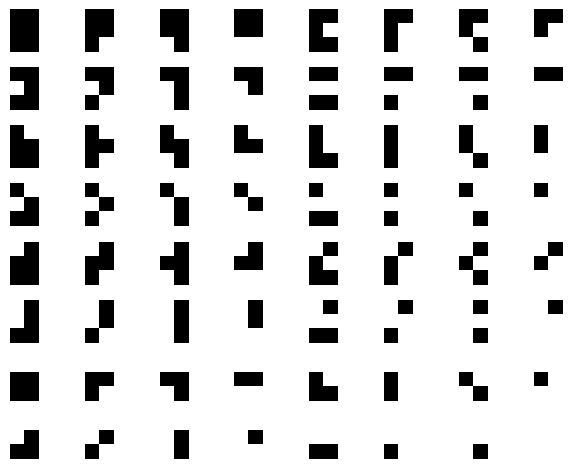

In [12]:
import numpy as np
import matplotlib.pyplot as plt

for i in range(64):
  num = format(i, '06b')

  num_array = np.array([int(j) for j in num])
  image = num_array.reshape(3,2)

  plt.subplot(8,8,i+1)
  plt.imshow(image, cmap='gray', vmin=0, vmax=1)
  plt.axis('off')

plt.tight_layout()
plt.show()

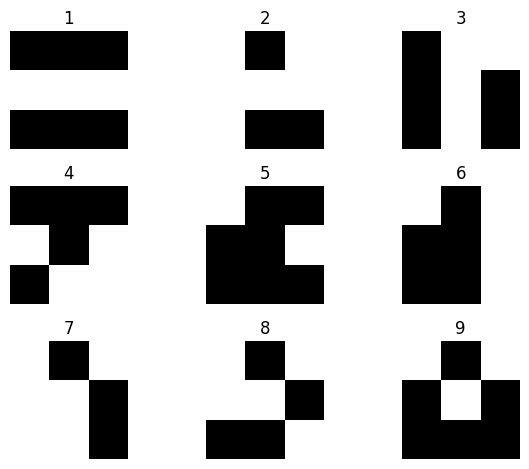

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import random

for i in range(9):
  num = random.randint(0,512)
  num = format(num, '09b')

  image = np.array([int(j) for j in num])
  image = image.reshape(3,3)

  plt.subplot(3,3,i+1)
  plt.imshow(image, cmap='gray')
  plt.axis('off')
  plt.title(f"{i+1}")

plt.tight_layout()
plt.show()

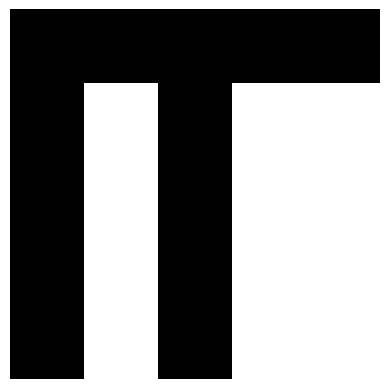

In [2]:
import numpy as np
import matplotlib.pyplot as plt

char = [[0,0,0,0,0],
        [0,1,0,1,1],
        [0,1,0,1,1],
        [0,1,0,1,1],
        [0,1,0,1,1]]

char = np.array(char)

plt.imshow(char, cmap='gray')
plt.axis('off')

plt.show()

57.49 %


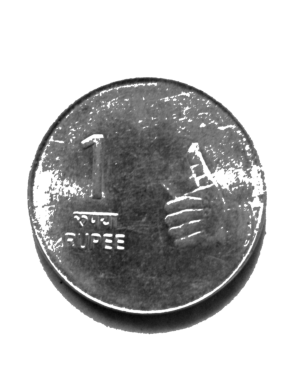

In [17]:
import numpy as np
import matplotlib.pyplot as plt

image = plt.imread("/content/coin1.jpg")

if image.ndim==3:
  gray = (image[:,:,0] * 0.299 +
          image[:,:,1] * 0.587 +
          image[:,:,2] * 0.114)
else:
  gray = image.copy()

if gray.max() <= 1:
    threshold = 150 / 255
    white = 1
else:
    threshold = 150
    white = 255

mask = gray > threshold
gray[mask] = white

coin_pixels = np.count_nonzero(mask)
total_pixels = gray.shape[0] * gray.shape[1]

percentage = coin_pixels / total_pixels * 100

print(round(percentage, 2), "%")

plt.imshow(gray,cmap = 'gray')
plt.axis('off')
plt.show()

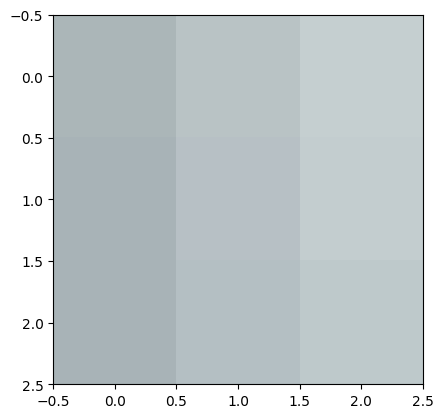

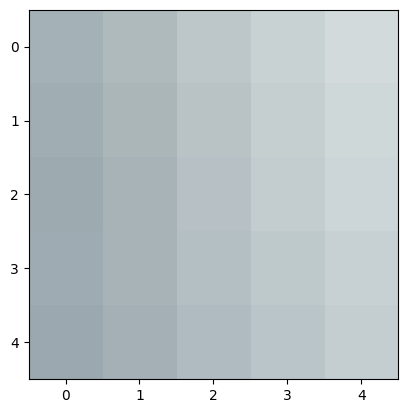

In [30]:
import numpy as np
import matplotlib.pyplot as plt

image = plt.imread("/content/coin1.jpg")

image = image[:,:,:3]

rows, cols, channels = image.shape

x = np.random.randint(2, rows-2)
y = np.random.randint(2, cols-2)

eight = image[x-1:x+2, y-1:y+2, :]
five = image[x-2:x+3, y-2:y+3, :]

plt.imshow(eight)
plt.show()

plt.imshow(five)
plt.show()

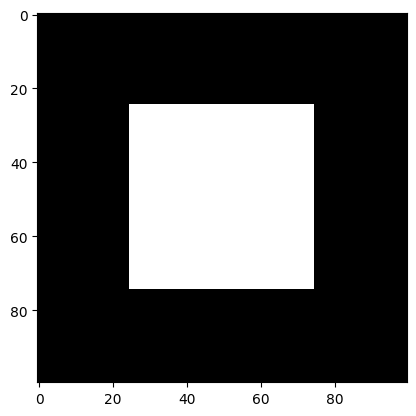

In [41]:
image = np.ones((100,100), dtype=np.uint8)*255
image[25:75, 25:75] = 0

negative = 255 - image

plt.imshow(negative, cmap='gray', vmin=0, vmax=255)
plt.show()


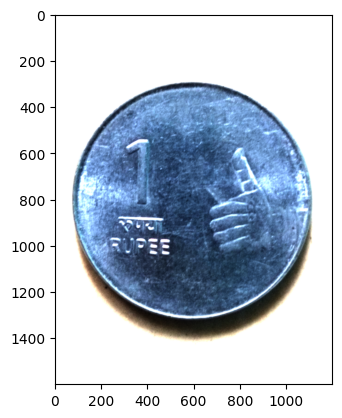

In [51]:
image = plt.imread('/content/coin1.jpg')

if image.max() > 1:
  image = image/255

image = 2 * (image ** 2)

plt.imshow(np.clip(image,0,1), cmap = 'gray')
plt.show()

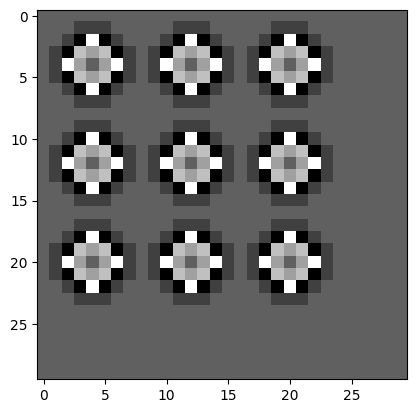

In [69]:
image = np.zeros([30,30])

for i in range(30):
    for j in range(30):
        if (i-4)**2 + (j-4)**2 <= 2**2:
            image[i, j] = 1
        if (i-12)**2 + (j-4)**2 <= 2**2:
            image[i, j] = 1
        if (i-20)**2 + (j-4)**2 <= 2**2:
            image[i, j] = 1
        if (i-4)**2 + (j-12)**2 <= 2**2:
            image[i, j] = 1
        if (i-12)**2 + (j-12)**2 <= 2**2:
            image[i, j] = 1
        if (i-20)**2 + (j-12)**2 <= 2**2:
            image[i, j] = 1
        if (i-4)**2 + (j-20)**2 <= 2**2:
            image[i, j] = 1
        if (i-12)**2 + (j-20)**2 <= 2**2:
            image[i, j] = 1
        if (i-20)**2 + (j-20)**2 <= 2**2:
            image[i, j] = 1

kernel = np.array([
    [-1,-1,-1],
    [-1,8,-1],
    [-1,-1,-1]
])

output = np.zeros([30,30])

for i in range(1,29):
  for j in range(1,29):
    total = 0
    for m in range(3):
      for n in range(3):
        total+=image[i+m-1, j+n-1] * kernel[m,n]

    output[i,j] = total

plt.imshow(output, cmap='gray')
plt.show()


5797.938253540751 6111.465615473888


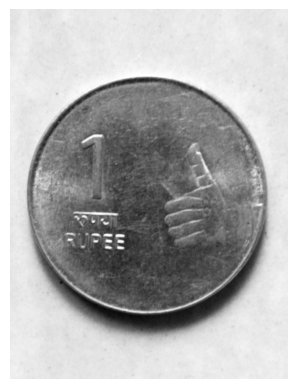

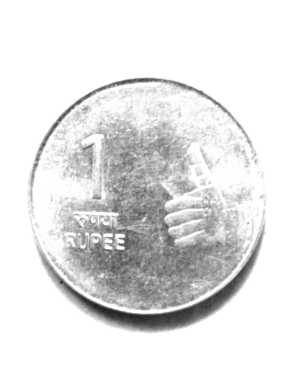

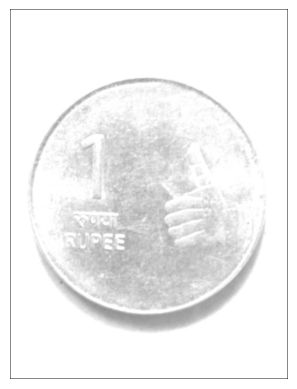

In [82]:
image = plt.imread("/content/coin1.jpg")

if image.ndim == 3:
    image = image[:, :, :3].mean(axis=2)

if image.max() <= 1:
    image = image * 255

image = image.astype(float)

noise = np.random.normal(110, 5, image.shape)

noisy = image + noise
noisy = np.clip(noisy, 0, 255)

kernel = np.array([
    [0.04,0.04,0.04,0.04,0.04],
    [0.04,0.04,0.04,0.04,0.04],
    [0.04,0.04,0.04,0.04,0.04],
    [0.04,0.04,0.04,0.04,0.04],
    [0.04,0.04,0.04,0.04,0.04]
])

rows, cols = noisy.shape
filtered = np.zeros((rows,cols))

for i in range(2, rows-2):
  for j in range(2, cols-2):
    total = 0
    for m in range(5):
      for n in range(5):
        total += noisy[i+m-2, j+n-2] * kernel[m,n]
    filtered[i][j] = total

mse_noisy = np.mean((image-noisy)**2)
mse_filtered = np.mean((image-filtered)**2)

print(mse_noisy, mse_filtered)

plt.imshow(image, cmap='gray')
plt.axis('off')
plt.show()

plt.imshow(noisy, cmap='gray')
plt.axis('off')
plt.show()

plt.imshow(filtered, cmap='gray')
plt.axis('off')
plt.show()

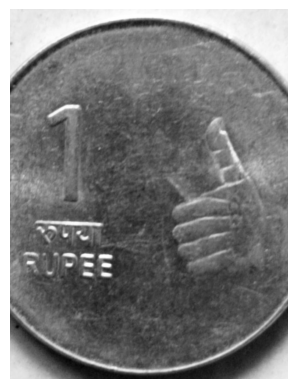

In [91]:
scaling = np.array([
    [1.5, 0],
    [0, 1.5]
])

image = plt.imread("/content/coin1.jpg")
image = image[:,:,:3].mean(axis=2)

rows, cols = image.shape
scaled = np.zeros_like(image)

cy = rows // 2
cx = cols // 2

inverse = np.linalg.inv(scaling)

for r in range(rows):
  for c in range(cols):
    x = c-cx
    y = r-cy

    new = inverse @ np.array([x,y])

    new_x = round(new[0] + cx)
    new_y = round(new[1] + cy)

    if (0 <= new_x < cols and
        0 <= new_y < rows):
        scaled[r, c] = image[new_y, new_x]

plt.imshow(scaled, cmap='gray')
plt.axis('off')
plt.show()

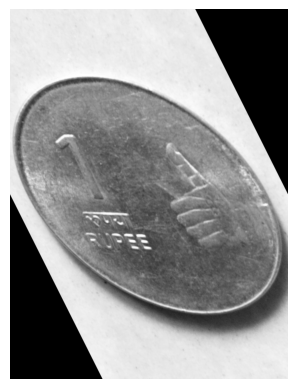

In [92]:
scaling = np.array([
    [1, 0.5],
    [0, 1]
])

image = plt.imread("/content/coin1.jpg")
image = image[:,:,:3].mean(axis=2)

rows, cols = image.shape
scaled = np.zeros_like(image)

cy = rows // 2
cx = cols // 2

inverse = np.linalg.inv(scaling)

for r in range(rows):
  for c in range(cols):
    x = c-cx
    y = r-cy

    new = inverse @ np.array([x,y])

    new_x = round(new[0] + cx)
    new_y = round(new[1] + cy)

    if (0 <= new_x < cols and
        0 <= new_y < rows):
        scaled[r, c] = image[new_y, new_x]

plt.imshow(scaled, cmap='gray')
plt.axis('off')
plt.show()

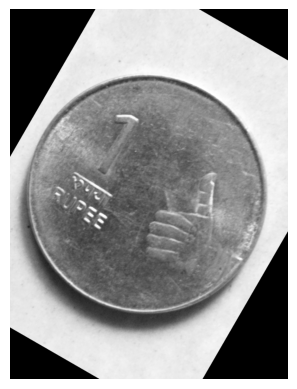

In [93]:
theta = 30 * np.pi / 180

scaling = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta), np.cos(theta)]
])

image = plt.imread("/content/coin1.jpg")
image = image[:,:,:3].mean(axis=2)

rows, cols = image.shape
scaled = np.zeros_like(image)

cy = rows // 2
cx = cols // 2

inverse = np.linalg.inv(scaling)

for r in range(rows):
  for c in range(cols):
    x = c-cx
    y = r-cy

    new = inverse @ np.array([x,y])

    new_x = round(new[0] + cx)
    new_y = round(new[1] + cy)

    if (0 <= new_x < cols and
        0 <= new_y < rows):
        scaled[r, c] = image[new_y, new_x]

plt.imshow(scaled, cmap='gray')
plt.axis('off')
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

img = plt.imread("selfie.jpg")

# Convert to grayscale
if img.ndim == 3:
    img = np.mean(img[:, :, :3], axis=2)

# Convert to 0-255 intensity values
if img.max() <= 1:
    img = img * 255

img = img.astype(np.uint8)

rows, cols = img.shape
cx = cols / 2
cy = rows / 2

# Choose one transformation matrix at a time.
theta = math.radians(30)

# Rotation matrix
T = [
    [math.cos(theta), -math.sin(theta)],
    [math.sin(theta),  math.cos(theta)]
]

# For scaling, replace T with:
# T = [[1.5, 0],
#      [0, 1.5]]

# For horizontal shear, replace T with:
# T = [[1, 0.5],
#      [0, 1]]

# Calculate inverse of the 2 x 2 matrix explicitly
a, b = T[0]
c, d = T[1]

det = a * d - b * c

invT = [
    [d / det, -b / det],
    [-c / det, a / det]
]

# Create blank output
output = np.zeros((rows, cols), dtype=np.uint8)

# Map each output pixel back to the input image
for y in range(rows):
    for x in range(cols):

        # Coordinates relative to image centre
        dx = x - cx
        dy = y - cy

        # Apply inverse transformation matrix
        sx = invT[0][0] * dx + invT[0][1] * dy
        sy = invT[1][0] * dx + invT[1][1] * dy

        # Convert back to original image coordinates
        sx = round(sx + cx)
        sy = round(sy + cy)

        # Copy only valid pixels
        if 0 <= sx < cols and 0 <= sy < rows:
            output[y, x] = img[sy, sx]

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(output, cmap='gray', vmin=0, vmax=255)
plt.title("Transformed")
plt.axis('off')

plt.show()

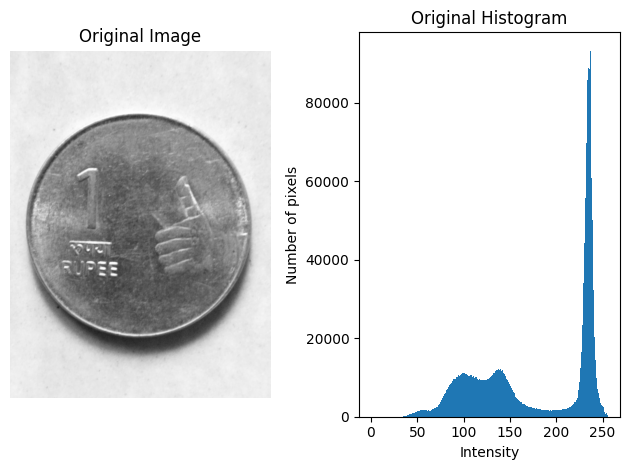

In [3]:
import numpy as np
import matplotlib.pyplot as plt

img = plt.imread("/content/coin1.jpg")

if img.ndim == 3:
    img = np.mean(img[:, :, :3], axis=2)

if img.max() <= 1:
    img = img * 255

img = img.astype(np.uint8)

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(img.ravel(), bins=256, range=(0, 256))
plt.title("Original Histogram")
plt.xlabel("Intensity")
plt.ylabel("Number of pixels")

plt.tight_layout()
plt.show()

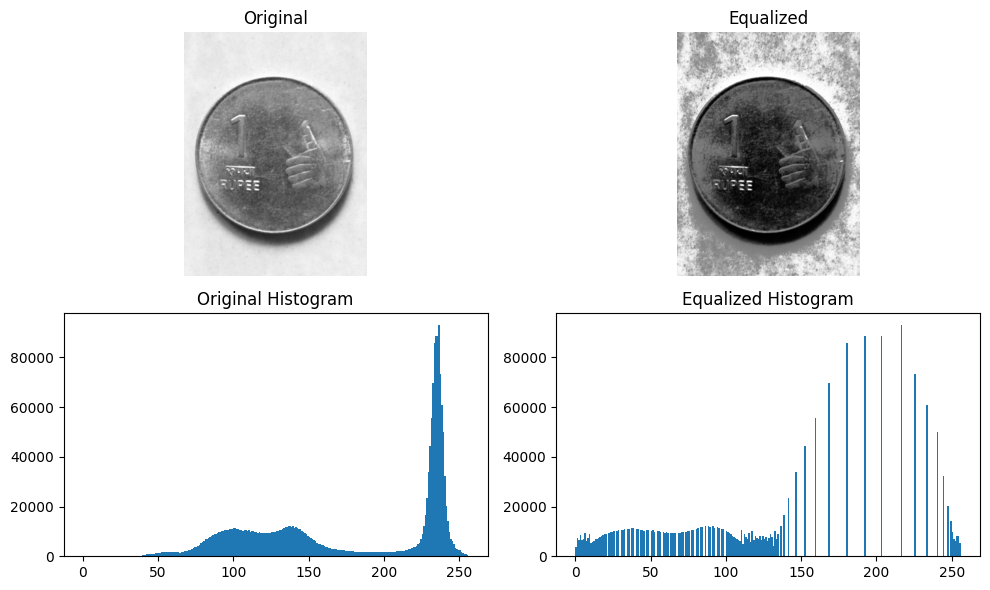

In [5]:
import numpy as np
import matplotlib.pyplot as plt

img = plt.imread("/content/coin1.jpg")

if img.ndim == 3:
    img = np.mean(img[:, :, :3], axis=2)

if img.max() <= 1:
    img = img * 255

img = img.astype(np.uint8)

# Calculate histogram
hist = np.zeros(256, dtype=int)

for pixel in img.ravel():
    hist[pixel] += 1

# Calculate cumulative histogram
cdf = np.cumsum(hist)

# Find first nonzero CDF value
cdf_min = cdf[np.nonzero(cdf)][0]

total = img.size

# Create intensity mapping
mapping = np.zeros(256, dtype=np.uint8)

for i in range(256):
    value = (cdf[i] - cdf_min) / (total - cdf_min)

    value = max(0, min(1, value))
    mapping[i] = round(value * 255)

# Apply mapping to every pixel
equalized = mapping[img]

# Display results
plt.figure(figsize=(10, 6))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title("Original")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(equalized, cmap='gray', vmin=0, vmax=255)
plt.title("Equalized")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.hist(img.ravel(), bins=256, range=(0, 256))
plt.title("Original Histogram")

plt.subplot(2, 2, 4)
plt.hist(equalized.ravel(), bins=256, range=(0, 256))
plt.title("Equalized Histogram")

plt.tight_layout()
plt.show()

plt.imsave("equalized.jpg", equalized, cmap='gray', vmin=0, vmax=255)